
OBJECTIVE (i)
--------------------------------
Training Accuracy: 0.6967
Validation Accuracy: 0.64
Test Accuracy: 0.58

OBJECTIVE (ii)
--------------------------------
W1 Gradient Shape: (2, 16)
b1 Gradient Shape: (1, 16)
W2 Gradient Shape: (16, 1)
b2 Gradient Shape: (1, 1)
Average |dW1|: 0.002342
Average |dW2|: 0.005998


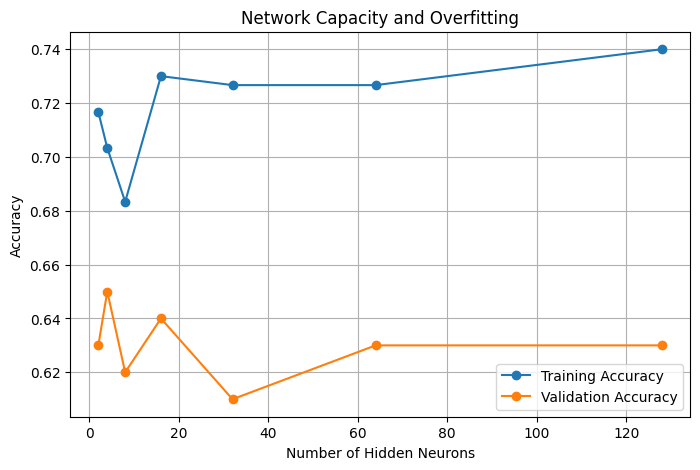


OBSERVATION (i): BIAS WEIGHT EXCLUSION
--------------------------------
W1 Weight Norm: 5.3422
W2 Weight Norm: 1.7605
b1 Bias Norm: 0.1705
b2 Bias Norm: 0.1799

L2 regularization is applied only to W1 and W2.
Bias parameters b1 and b2 are excluded.


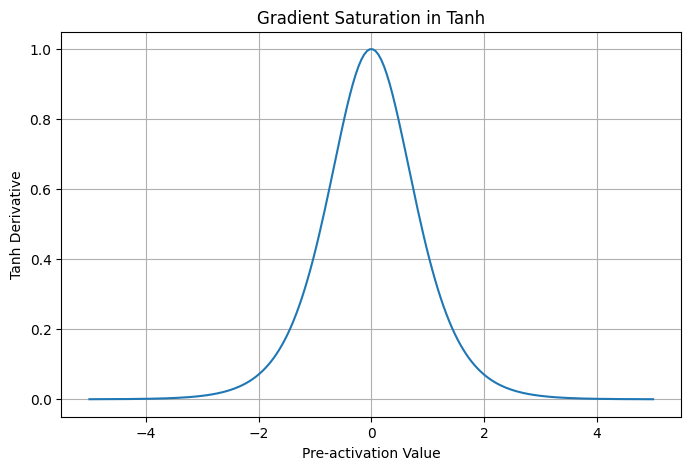


OBSERVATION (ii): GRADIENT SATURATION
--------------------------------

For large positive or negative values of z,
the derivative of tanh becomes close to zero.
Therefore, gradients become very small during
backpropagation. This is known as the vanishing
gradient problem.



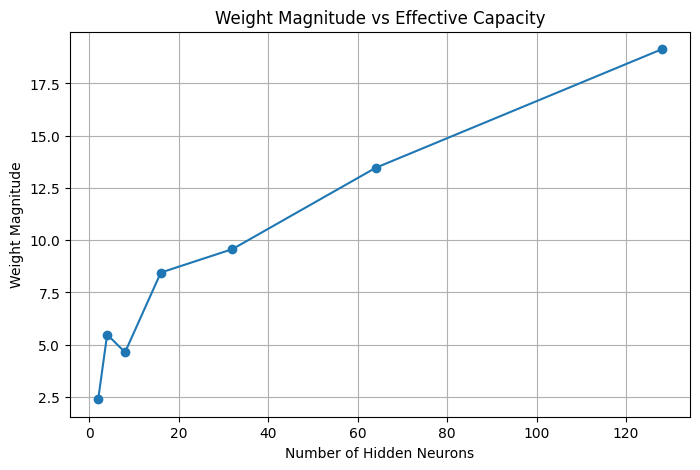


OBSERVATION (iii): WEIGHT MAGNITUDE AND EFFECTIVE CAPACITY
--------------------------------
Hidden Neurons: 2 | Weight Magnitude: 2.391 | Train Accuracy: 0.543 | Validation Accuracy: 0.48
Hidden Neurons: 4 | Weight Magnitude: 5.486 | Train Accuracy: 0.583 | Validation Accuracy: 0.57
Hidden Neurons: 8 | Weight Magnitude: 4.637 | Train Accuracy: 0.63 | Validation Accuracy: 0.58
Hidden Neurons: 16 | Weight Magnitude: 8.45 | Train Accuracy: 0.717 | Validation Accuracy: 0.65
Hidden Neurons: 32 | Weight Magnitude: 9.572 | Train Accuracy: 0.713 | Validation Accuracy: 0.61
Hidden Neurons: 64 | Weight Magnitude: 13.459 | Train Accuracy: 0.713 | Validation Accuracy: 0.62
Hidden Neurons: 128 | Weight Magnitude: 19.136 | Train Accuracy: 0.723 | Validation Accuracy: 0.66

OBSERVATION (iv): EARLY STOPPING VS WEIGHT DECAY
--------------------------------

L2 WEIGHT DECAY
Training Accuracy: 0.7333
Validation Accuracy: 0.62
Test Accuracy: 0.64

EARLY STOPPING
Training Accuracy: 0.76
Validation Accurac

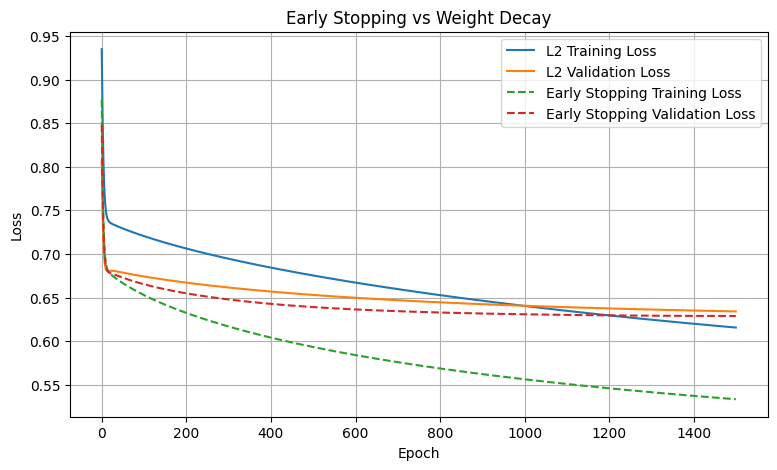

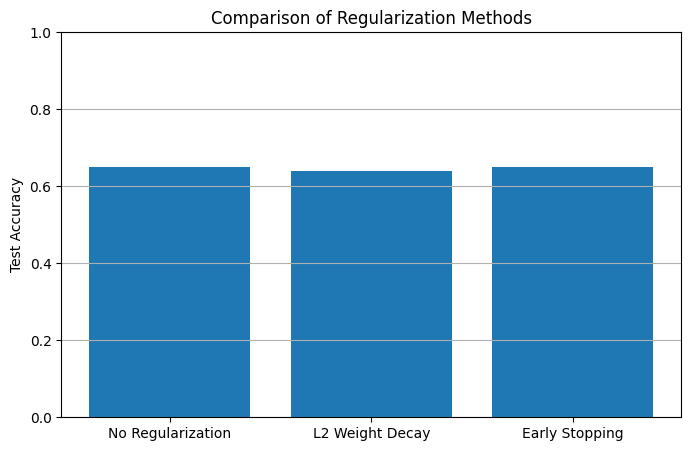

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate noisy data
X = np.random.uniform(-3, 3, (500, 2))

y = (
    np.sin(2 * X[:, 0]) +
    np.cos(2 * X[:, 1]) > 0
).astype(float)

noise = np.random.rand(500) < 0.15
y[noise] = 1 - y[noise]

# Split data
idx = np.random.permutation(500)

train_idx = idx[:300]
val_idx = idx[300:400]
test_idx = idx[400:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]


def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2


class MLP:

    def __init__(self, input_size, hidden_size):

        self.W1 = (
            np.random.randn(input_size, hidden_size)
            * np.sqrt(2 / input_size)
        )

        self.b1 = np.zeros((1, hidden_size))

        self.W2 = (
            np.random.randn(hidden_size, 1)
            * np.sqrt(2 / hidden_size)
        )

        self.b2 = np.zeros((1, 1))

    def forward(self, X):

        self.z1 = X @ self.W1 + self.b1
        self.a1 = np.tanh(self.z1)

        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = sigmoid(self.z2)

        return self.a2

    def loss(self, y, prediction, l2=0):

        y = y.reshape(-1, 1)

        cross_entropy = -np.mean(
            y * np.log(prediction + 1e-8)
            + (1 - y) * np.log(1 - prediction + 1e-8)
        )

        penalty = (l2 / 2) * (
            np.sum(self.W1**2) +
            np.sum(self.W2**2)
        )

        return cross_entropy + penalty

    def backward(self, X, y, l2=0):

        self.forward(X)

        m = len(X)
        y = y.reshape(-1, 1)

        dz2 = self.a2 - y

        dW2 = self.a1.T @ dz2 / m
        db2 = dz2.sum(axis=0, keepdims=True) / m

        dz1 = (
            dz2 @ self.W2.T
        ) * tanh_derivative(self.z1)

        dW1 = X.T @ dz1 / m
        db1 = dz1.sum(axis=0, keepdims=True) / m

        return (
            dW1 + l2 * self.W1,
            db1,
            dW2 + l2 * self.W2,
            db2
        )

    def update(self, gradients, learning_rate):

        dW1, db1, dW2, db2 = gradients

        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

    def predict(self, X):
        return (
            self.forward(X) >= 0.5
        ).astype(int).ravel()

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == y)


def train_model(
    hidden_size,
    epochs=1000,
    learning_rate=0.03,
    l2=0,
    early_stopping=False,
    patience=50
):

    model = MLP(2, hidden_size)

    train_losses = []
    val_losses = []

    best_loss = float("inf")
    best_weights = None
    wait = 0

    for _ in range(epochs):

        model.update(
            model.backward(X_train, y_train, l2),
            learning_rate
        )

        train_loss = model.loss(
            y_train,
            model.forward(X_train),
            l2
        )

        val_loss = model.loss(
            y_val,
            model.forward(X_val)
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if early_stopping:

            if val_loss < best_loss:

                best_loss = val_loss

                best_weights = tuple(
                    w.copy()
                    for w in (
                        model.W1,
                        model.b1,
                        model.W2,
                        model.b2
                    )
                )

                wait = 0

            else:

                wait += 1

                if wait >= patience:
                    break

    if early_stopping and best_weights is not None:

        model.W1, model.b1, model.W2, model.b2 = best_weights

    return model, train_losses, val_losses


def print_accuracies(model):

    for name, data, labels in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test),
    ]:

        print(
            f"{name} Accuracy:",
            round(model.accuracy(data, labels), 4)
        )


# Train main network
model, train_loss, val_loss = train_model(16)

print("\nOBJECTIVE (i)")
print("--------------------------------")
print_accuracies(model)

# Print gradients
print("\nOBJECTIVE (ii)")
print("--------------------------------")

dW1, db1, dW2, db2 = model.backward(
    X_train, y_train
)

for name, gradient in [
    ("W1", dW1),
    ("b1", db1),
    ("W2", dW2),
    ("b2", db2)
]:

    print(f"{name} Gradient Shape:", gradient.shape)

print(
    "Average |dW1|:",
    round(np.mean(np.abs(dW1)), 6)
)

print(
    "Average |dW2|:",
    round(np.mean(np.abs(dW2)), 6)
)

# Compare network sizes
hidden_sizes = [2, 4, 8, 16, 32, 64, 128]

train_accuracies = []
validation_accuracies = []

for size in hidden_sizes:

    net, _, _ = train_model(
        size,
        epochs=1500
    )

    train_accuracies.append(
        net.accuracy(X_train, y_train)
    )

    validation_accuracies.append(
        net.accuracy(X_val, y_val)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    hidden_sizes,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    hidden_sizes,
    validation_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Number of Hidden Neurons")
plt.ylabel("Accuracy")
plt.title("Network Capacity and Overfitting")
plt.legend()
plt.grid()
plt.show()

# Biases are excluded from L2 regularization
print("\nOBSERVATION (i): BIAS WEIGHT EXCLUSION")
print("--------------------------------")

for name, weights in [
    ("W1 Weight Norm:", model.W1),
    ("W2 Weight Norm:", model.W2),
    ("b1 Bias Norm:", model.b1),
    ("b2 Bias Norm:", model.b2),
]:

    print(name, round(np.linalg.norm(weights), 4))

print("\nL2 regularization is applied only to W1 and W2.")
print("Bias parameters b1 and b2 are excluded.")

# Show tanh gradient saturation
z_values = np.linspace(-5, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(z_values, tanh_derivative(z_values))

plt.xlabel("Pre-activation Value")
plt.ylabel("Tanh Derivative")
plt.title("Gradient Saturation in Tanh")
plt.grid()
plt.show()

print("\nOBSERVATION (ii): GRADIENT SATURATION")
print("--------------------------------")

print("""
For large positive or negative values of z,
the derivative of tanh becomes close to zero.
Therefore, gradients become very small during
backpropagation. This is known as the vanishing
gradient problem.
""")

# Compare weight magnitude across network sizes
weight_norms = []
capacity_train_accuracy = []
capacity_val_accuracy = []

for size in hidden_sizes:

    net, _, _ = train_model(
        size,
        epochs=1000
    )

    weight_norms.append(
        np.linalg.norm(net.W1) +
        np.linalg.norm(net.W2)
    )

    capacity_train_accuracy.append(
        net.accuracy(X_train, y_train)
    )

    capacity_val_accuracy.append(
        net.accuracy(X_val, y_val)
    )

plt.figure(figsize=(8, 5))
plt.plot(hidden_sizes, weight_norms, marker="o")

plt.xlabel("Number of Hidden Neurons")
plt.ylabel("Weight Magnitude")
plt.title("Weight Magnitude vs Effective Capacity")
plt.grid()
plt.show()

print("\nOBSERVATION (iii): WEIGHT MAGNITUDE AND EFFECTIVE CAPACITY")
print("--------------------------------")

for size, weight, train_acc, val_acc in zip(
    hidden_sizes,
    weight_norms,
    capacity_train_accuracy,
    capacity_val_accuracy
):

    print(
        "Hidden Neurons:", size,
        "| Weight Magnitude:", round(weight, 3),
        "| Train Accuracy:", round(train_acc, 3),
        "| Validation Accuracy:", round(val_acc, 3)
    )

# Compare L2 regularization and early stopping
model_l2, train_l2, val_l2 = train_model(
    64,
    epochs=1500,
    l2=0.001
)

model_early, train_early, val_early = train_model(
    64,
    epochs=1500,
    early_stopping=True,
    patience=60
)

print("\nOBSERVATION (iv): EARLY STOPPING VS WEIGHT DECAY")
print("--------------------------------")

print("\nL2 WEIGHT DECAY")
print_accuracies(model_l2)

print("\nEARLY STOPPING")
print_accuracies(model_early)

plt.figure(figsize=(9, 5))

plt.plot(train_l2, label="L2 Training Loss")
plt.plot(val_l2, label="L2 Validation Loss")

plt.plot(
    train_early,
    "--",
    label="Early Stopping Training Loss"
)

plt.plot(
    val_early,
    "--",
    label="Early Stopping Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping vs Weight Decay")
plt.legend()
plt.grid()
plt.show()

# Compare test accuracy with no regularization
normal_model, _, _ = train_model(
    64,
    epochs=1500
)

results = [
    normal_model.accuracy(X_test, y_test),
    model_l2.accuracy(X_test, y_test),
    model_early.accuracy(X_test, y_test),
]

plt.figure(figsize=(8, 5))

plt.bar(
    [
        "No Regularization",
        "L2 Weight Decay",
        "Early Stopping"
    ],
    results
)

plt.ylabel("Test Accuracy")
plt.title("Comparison of Regularization Methods")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()